# Customer 360 Intelligence - Practical Machine Learning Workshop


## 1. Imports

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

## 2. Load Dataset

In [2]:
df = pd.read_csv("customer_360_ml_workshop.csv")
df.head()

,CustomerID,Age,Region,TenureMonths,ContractType,InternetType,MonthlyUsageGB,MonthlyChargeEGP,NumServices,SupportCalls6M,LatePayments12M,PaperlessBilling,AutoPay,SatisfactionScore,Future12MRevenueEGP,Churn
0,CUST-00001,22,Alexandria,23,Month-to-month,DSL,317.9,580.48,5,5,0,Yes,Yes,5.0,6287.08,Yes
1,CUST-00002,59,Upper Egypt,9,Month-to-month,4G/5G,359.3,434.36,1,1,1,No,Yes,4.0,4619.91,No
2,CUST-00003,52,Giza,21,Month-to-month,DSL,176.9,391.35,3,5,1,Yes,Yes,5.0,4512.25,No
3,CUST-00004,41,Giza,12,Month-to-month,DSL,312.5,420.40,3,2,1,No,Yes,5.0,3809.65,No
4,CUST-00005,40,Delta,21,Month-to-month,4G/5G,191.6,462.73,3,4,0,No,Yes,3.0,4731.09,No


##  Part B - Data Preprocessing

##  Regression Train/Test Split

In [3]:
y_regression = df["Future12MRevenueEGP"]
X_regression = df.drop(columns=["CustomerID", "Future12MRevenueEGP", "Churn"])

print("X_regression shape:", X_regression.shape)
print("y_regression shape:", y_regression.shape)
print()
print("Regression features:")
print(list(X_regression.columns))
print()
print("CustomerID in features:", "CustomerID" in X_regression.columns)
print("Future12MRevenueEGP in features:", "Future12MRevenueEGP" in X_regression.columns)
print("Churn in features:", "Churn" in X_regression.columns)

X_regression shape: (3000, 13)
y_regression shape: (3000,)

Regression features:
['Age', 'Region', 'TenureMonths', 'ContractType', 'InternetType', 'MonthlyUsageGB', 'MonthlyChargeEGP', 'NumServices', 'SupportCalls6M', 'LatePayments12M', 'PaperlessBilling', 'AutoPay', 'SatisfactionScore']

CustomerID in features: False
Future12MRevenueEGP in features: False
Churn in features: False


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_regression, y_regression, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)
print()
print("Average revenue in train set:", round(y_train.mean(), 2))
print("Average revenue in test set:", round(y_test.mean(), 2))

X_train: (2400, 13)
X_test: (600, 13)
y_train: (2400,)
y_test: (600,)

Average revenue in train set: 5343.58
Average revenue in test set: 5431.46


##  Preprocessing Pipeline

In [5]:
numeric_features = X_train.select_dtypes(include="number").columns.tolist()
categorical_features = X_train.select_dtypes(exclude="number").columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
preprocessor

Numeric features: ['Age', 'TenureMonths', 'MonthlyUsageGB', 'MonthlyChargeEGP', 'NumServices', 'SupportCalls6M', 'LatePayments12M', 'SatisfactionScore']
Categorical features: ['Region', 'ContractType', 'InternetType', 'PaperlessBilling', 'AutoPay']


,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### Fitting on the training data and transforming both sets

In [6]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
X_train_processed_df = pd.DataFrame(X_train_processed, columns=feature_names)
X_test_processed_df = pd.DataFrame(X_test_processed, columns=feature_names)

print("Processed X_train shape:", X_train_processed.shape)
print("Processed X_test shape:", X_test_processed.shape)
print("Missing values after preprocessing (train):", int(np.isnan(X_train_processed).sum()))
print("Missing values after preprocessing (test):", int(np.isnan(X_test_processed).sum()))
print()

learned_medians = pd.Series(
    preprocessor.named_transformers_["num"].named_steps["imputer"].statistics_,
    index=numeric_features
)
print("Medians learned from the training data only:")
print(learned_medians.round(2))
print()

num_cols_processed = ["num__" + col for col in numeric_features]
scaled_check = pd.DataFrame({
    "train_mean": X_train_processed_df[num_cols_processed].mean().round(3),
    "train_std": X_train_processed_df[num_cols_processed].std().round(3),
    "test_mean": X_test_processed_df[num_cols_processed].mean().round(3)
})
print("Scaled numerical columns (train is centered, test is not exactly centered):")
print(scaled_check)
print()
X_train_processed_df.head()

Processed X_train shape: (2400, 23)
Processed X_test shape: (600, 23)
Missing values after preprocessing (train): 0
Missing values after preprocessing (test): 0

Medians learned from the training data only:
Age                   44.00
TenureMonths          22.00
MonthlyUsageGB       229.10
MonthlyChargeEGP     484.46
NumServices            4.00
SupportCalls6M         2.00
LatePayments12M        1.00
SatisfactionScore      4.00
dtype: float64

Scaled numerical columns (train is centered, test is not exactly centered):
                        train_mean  train_std  test_mean
num__Age                      -0.0        1.0     -0.024
num__TenureMonths              0.0        1.0     -0.043
num__MonthlyUsageGB           -0.0        1.0     -0.010
num__MonthlyChargeEGP          0.0        1.0      0.049
num__NumServices              -0.0        1.0      0.034
num__SupportCalls6M            0.0        1.0      0.016
num__LatePayments12M           0.0        1.0     -0.048
num__SatisfactionScor

,num__Age,num__TenureMonths,num__MonthlyUsageGB,num__MonthlyChargeEGP,num__NumServices,num__SupportCalls6M,num__LatePayments12M,num__SatisfactionScore,cat__Region_Alexandria,cat__Region_Cairo,cat__Region_Delta,cat__Region_Giza,cat__Region_Upper Egypt,cat__ContractType_Month-to-month,cat__ContractType_One year,cat__ContractType_Two year,cat__InternetType_4G/5G,cat__InternetType_DSL,cat__InternetType_Fiber,cat__PaperlessBilling_No,cat__PaperlessBilling_Yes,cat__AutoPay_No,cat__AutoPay_Yes
0,1.230453,-0.768110,-1.039078,-0.671456,-0.873305,-0.805268,2.682643,1.497032,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
1,0.056600,-0.283641,0.012739,-2.385064,-1.454217,-0.135142,0.818887,-2.468616,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2,1.034811,1.351440,-0.917408,-0.160390,0.288520,-0.135142,-1.044868,0.505620,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
3,-1.247680,-0.949786,1.562607,1.134739,0.288520,-0.805268,-1.044868,1.497032,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
4,-0.791182,0.866972,-1.546225,-1.957895,-1.454217,0.534984,0.818887,-1.477204,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


##  Part D - Regression Models

In [7]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=42),
    "Lasso": Lasso(alpha=1.0, random_state=42),
    "KNN Regressor": KNeighborsRegressor(n_neighbors=5),
    "Decision Tree Regressor": DecisionTreeRegressor(max_depth=5, random_state=42),
    "Random Forest Regressor": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42)
}

kfold = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

cv_rows = []
for name, model in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    scores = cross_validate(pipeline, X_train, y_train, cv=kfold, scoring=scoring)
    cv_rows.append({
        "Model": name,
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_R2": scores["test_r2"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values("CV_RMSE").reset_index(drop=True)
cv_results.round(4)

,Model,CV_MAE,CV_RMSE,CV_R2
0,Gradient Boosting Regressor,365.3137,463.9905,0.9023
1,Lasso,372.3393,471.7573,0.8988
2,Ridge,372.7187,472.0829,0.8987
3,Linear Regression,372.7480,472.0966,0.8987
4,Random Forest Regressor,382.5866,485.6014,0.8931
5,Decision Tree Regressor,407.3360,514.7183,0.8800
6,KNN Regressor,591.4984,749.2331,0.7454


### Selecting the final model

In [8]:
final_model_name = cv_results.loc[0, "Model"]
print("Model selected using training-set cross-validation (lowest CV RMSE):", final_model_name)

Model selected using training-set cross-validation (lowest CV RMSE): Gradient Boosting Regressor


##  Model Evaluation

In [9]:
results_rows = []
predictions = {}
fitted_pipelines = {}

for name, model in models.items():
    pipeline = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    fitted_pipelines[name] = pipeline
    predictions[name] = y_pred
    results_rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "R2": r2_score(y_test, y_pred)
    })

results = pd.DataFrame(results_rows)
baseline_prediction = np.full(len(y_test), y_train.mean())
print("Baseline MAE (always predicting the training-set mean revenue):", round(mean_absolute_error(y_test, baseline_prediction), 2))
print("Average actual revenue in the test set:", round(y_test.mean(), 2))

Baseline MAE (always predicting the training-set mean revenue): 1172.53
Average actual revenue in the test set: 5431.46


## Regression Comparison Table

In [10]:
results_table = results.sort_values("RMSE").reset_index(drop=True)
results_table[["MAE", "RMSE", "R2"]] = results_table[["MAE", "RMSE", "R2"]].round(4)
results_table

,Model,MAE,RMSE,R2
0,Gradient Boosting Regressor,368.5602,464.9723,0.8968
1,Ridge,378.4166,474.9148,0.8923
2,Linear Regression,378.4270,474.9281,0.8923
3,Lasso,378.6725,475.0863,0.8923
4,Random Forest Regressor,392.5880,495.6261,0.8828
5,Decision Tree Regressor,419.0579,534.6587,0.8636
6,KNN Regressor,619.2911,783.4992,0.7070


## Actual vs Predicted Visualization

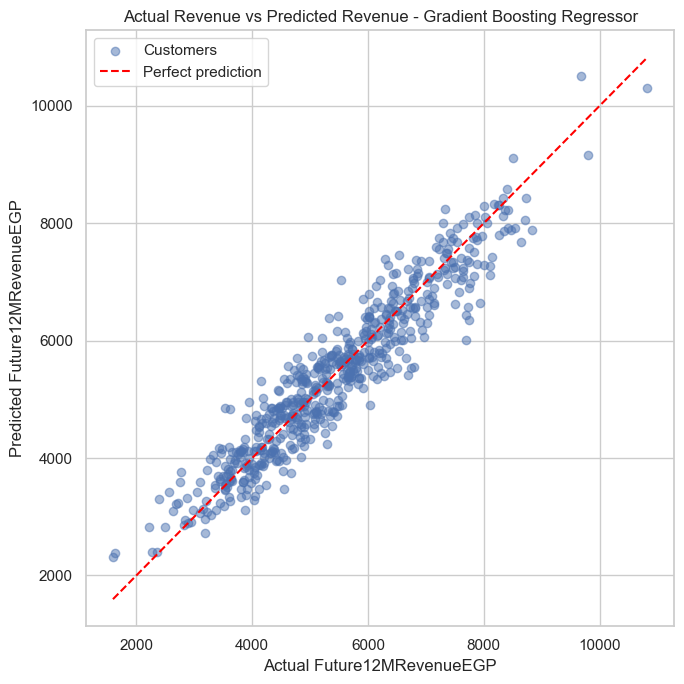

MAE : 368.56
RMSE: 464.97
R2  : 0.8968


In [11]:
final_predictions = predictions[final_model_name]
final_row = results[results["Model"] == final_model_name].iloc[0]

plt.figure(figsize=(7, 7))
plt.scatter(y_test, final_predictions, alpha=0.5, label="Customers")
axis_min = min(y_test.min(), final_predictions.min())
axis_max = max(y_test.max(), final_predictions.max())
plt.plot([axis_min, axis_max], [axis_min, axis_max], color="red", linestyle="--", label="Perfect prediction")
plt.xlabel("Actual Future12MRevenueEGP")
plt.ylabel("Predicted Future12MRevenueEGP")
plt.title("Actual Revenue vs Predicted Revenue - " + final_model_name)
plt.legend()
plt.tight_layout()
plt.show()

print("MAE :", round(final_row["MAE"], 2))
print("RMSE:", round(final_row["RMSE"], 2))
print("R2  :", round(final_row["R2"], 4))

### Residual analysis

Mean residual (bias)                          18.26
Std of residuals                             465.00
Smallest residual                          -1498.64
Largest residual                            1671.68
Errors larger than 2 x RMSE                   27.00
Share of errors larger than 2 x RMSE (%)       4.50
dtype: float64

Error by actual revenue group
                      customers     MAE  mean_residual
Future12MRevenueEGP                                   
Q1 (lowest revenue)         150  340.24        -149.82
Q2                          150  358.73         -35.82
Q3                          150  342.85          55.42
Q4 (highest revenue)        150  432.41         203.27


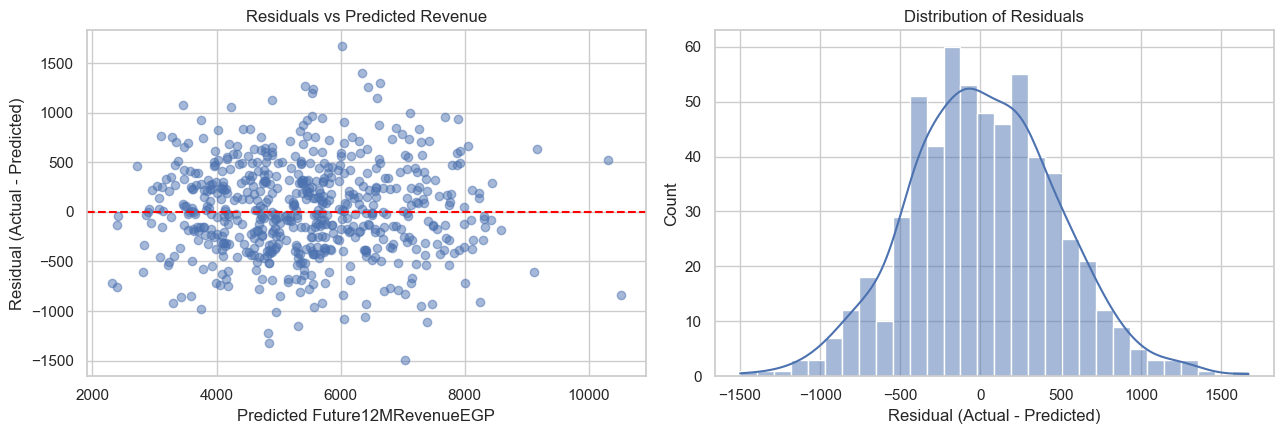

In [12]:
residuals = y_test - final_predictions
final_rmse = final_row["RMSE"]

residual_summary = pd.Series({
    "Mean residual (bias)": residuals.mean(),
    "Std of residuals": residuals.std(),
    "Smallest residual": residuals.min(),
    "Largest residual": residuals.max(),
    "Errors larger than 2 x RMSE": int((residuals.abs() > 2 * final_rmse).sum()),
    "Share of errors larger than 2 x RMSE (%)": (residuals.abs() > 2 * final_rmse).mean() * 100
})
print(residual_summary.round(2))
print()

revenue_band = pd.qcut(y_test, 4, labels=["Q1 (lowest revenue)", "Q2", "Q3", "Q4 (highest revenue)"])
band_table = pd.DataFrame({
    "abs_error": residuals.abs(),
    "residual": residuals
}).groupby(revenue_band, observed=True).agg(
    customers=("abs_error", "size"),
    MAE=("abs_error", "mean"),
    mean_residual=("residual", "mean")
).round(2)
print("Error by actual revenue group")
print(band_table)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].scatter(final_predictions, residuals, alpha=0.5)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Predicted Future12MRevenueEGP")
axes[0].set_ylabel("Residual (Actual - Predicted)")
axes[0].set_title("Residuals vs Predicted Revenue")
sns.histplot(residuals, bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Residuals")
axes[1].set_xlabel("Residual (Actual - Predicted)")
plt.tight_layout()
plt.show()

### What drives the final model?

The most important features of the selected model.

In [13]:
final_pipeline = fitted_pipelines[final_model_name]
final_estimator = final_pipeline.named_steps["model"]
final_feature_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()

if hasattr(final_estimator, "feature_importances_"):
    importance_values = final_estimator.feature_importances_
else:
    importance_values = np.abs(final_estimator.coef_)

importance_table = pd.Series(importance_values, index=final_feature_names).sort_values(ascending=False)
print("Top 8 most important features for", final_model_name)
print(importance_table.head(8).round(4))

Top 8 most important features for Gradient Boosting Regressor
num__MonthlyChargeEGP               0.7881
cat__ContractType_Month-to-month    0.1483
cat__ContractType_Two year          0.0434
num__TenureMonths                   0.0058
num__LatePayments12M                0.0047
num__SatisfactionScore              0.0030
num__MonthlyUsageGB                 0.0030
num__NumServices                    0.0009
dtype: float64


##  Final Interpretation

### Model comparison

| Model | MAE (EGP) | RMSE (EGP) | R² |
|---|---|---|---|
| Gradient Boosting Regressor | 368.56 | 464.97 | 0.8968 |
| Ridge | 378.42 | 474.91 | 0.8923 |
| Linear Regression | 378.43 | 474.93 | 0.8923 |
| Lasso | 378.67 | 475.09 | 0.8923 |
| Random Forest Regressor | 392.59 | 495.63 | 0.8828 |
| Decision Tree Regressor | 419.06 | 534.66 | 0.8636 |
| KNN Regressor | 619.29 | 783.50 | 0.7070 |

### Best model

**Gradient Boosting Regressor** has the strongest results: it is first in the training cross-validation (RMSE 463.99) and also first on the test set with the lowest MAE (368.56), the lowest RMSE (464.97) and the highest R² (0.8968). Its advantage is small: the three linear models are practically tied with each other (RMSE about 475) and are only about 10 EGP of RMSE and 0.0045 of R² behind. Only KNN and, to a smaller extent, the Decision Tree fall clearly behind.

### Why it performed better

- Revenue is mostly explained by MonthlyChargeEGP (importance 0.7881) and ContractType (month-to-month 0.1483, two-year 0.0434); all other features have importance below 0.01. Such a strong, simple structure is why even the linear models reach R² of 0.8923.
- Gradient Boosting builds many small trees in sequence, each correcting the errors of the previous ones. This likely lets it capture small non-linear effects on top of the main linear relationship, which explains its small edge.
- Ridge, Lasso and Linear Regression give almost identical scores, so regularization brings no visible benefit here (with only 23 processed features and 2,400 training rows there is little overfitting to reduce).
- KNN is clearly the weakest. A likely reason is that it averages neighbours in a space of 23 features where most of them barely relate to revenue, so the distance is dominated by irrelevant features. The depth-limited Decision Tree and the Random Forest are also behind, though the reasons were not tested here.
- Hyperparameters were not tuned, so the ranking reflects sensible default settings and not the maximum each model could reach.

### Systematic errors and outliers

- **Average bias is small:** the mean residual is 18.26 EGP, very small compared with the RMSE of 464.97.
- **There is a pattern by revenue level:** the model over-predicts low-revenue customers (mean residual -149.82 in the lowest quarter) and under-predicts the highest-revenue customers (+203.27 in the top quarter). The MAE is also highest for the top quarter (432.41) compared with 340.24 - 358.73 for the others. The model is pulled towards the average, so it is least reliable for the most valuable customers.
- **Large errors are few but exist:** 27 of 600 test customers (4.50%) have an error larger than 2 x RMSE, and the residuals range from -1,498.64 to +1,671.68 EGP.

### Business meaning

- On average the model is wrong by about 369 EGP per customer for the next 12 months. Compared with the average test revenue of 5,431.46 EGP this is about 6.8%, and it is far better than the baseline that predicts the mean for everyone (MAE 1,172.53 EGP).
- With R² = 0.8968, the model explains about 90% of the variation in future revenue. It is suitable for ranking customers by expected value, for revenue forecasting and for deciding where to focus retention and upselling budgets.
- It should be used with caution for the top revenue group, whose value tends to be under-estimated by about 203 EGP on average.
- Because revenue depends mainly on the monthly charge and contract type, the model mostly captures the billing and commitment structure of the customer base. Business actions that change these two variables (longer contracts, more services) are the ones expected to move future revenue.
- The residual diagnostics and conclusions above describe this synthetic dataset and this single train/test split.

##  Final Checklist

**Part A - Business Understanding & EDA**
- [x] Dataset loaded; head, shape, columns, data types and info displayed
- [x] Missing values investigated (counts and percentages)
- [x] Descriptive statistics for numerical variables
- [x] Categorical variables and frequencies
- [x] Churn distribution (counts, percentages, plots)
- [x] Histograms and boxplots of numerical variables
- [x] Churn by ContractType and by AutoPay
- [x] Numerical variables vs churn and vs revenue (correlations)
- [x] Data-quality issues, skewness and outliers checked
- [x] Identifier, targets and excluded features identified and explained
- [x] Q1 - Q4 answered
- [x] More than five business observations based on real results

**Part B - Data Preprocessing**
- [x] CustomerID, Future12MRevenueEGP and Churn removed from the regression features
- [x] X_regression / y_regression separated, 80/20 split with random_state=42
- [x] Median imputation + StandardScaler for numerical features
- [x] Most-frequent imputation + OneHotEncoder(handle_unknown="ignore") for categorical features
- [x] ColumnTransformer and Pipeline used; fitted on training data only

**Part D - Revenue Regression**
- [x] Seven models compared: Linear Regression, Ridge, Lasso, KNN, Decision Tree, Random Forest, Gradient Boosting
- [x] Same preprocessing pipeline for every model; random_state=42 wherever supported
- [x] Model selection by cross-validation on the training set; test set kept for final evaluation
- [x] MAE, RMSE and R² reported in a comparison table
- [x] Actual vs Predicted Revenue scatter plot with a perfect-prediction line
- [x] Interpretation: best model, why, systematic errors and outliers, business meaning